# Gated attention — 05: Carry-over between unrelated stories

During training, stories are packed back to back, so a model can always attend to the previous story. Does access to an unrelated story **A** hurt the prediction of the next story **B**? And does gating (or a sink) make a model better at ignoring A?

**Part A — natural boundaries.** For every saved `EOS A EOS B` sequence (notebook 01) each model is run twice on **identical tokens and position ids**:
- **ordinary**: normal causal attention (B can see A);
- **masked**: in every layer, the EOS before B and all B queries are blocked from attending to A (EOS is treated as the start of B's segment, so A cannot leak through it, and the EOS position still predicts B's first token). Attention inside B is unchanged.

**Interference cost** = ordinary loss − masked loss on B's targets. Positive ⇒ access to the previous story hurt.

**Part B — controlled name intrusion.** Two versions of A differ only in the protagonist's name (Lily vs Emma). Both are followed by the same B about a third person, ending where a name is a natural next word. We measure whether A's protagonist leaks into B's prediction.

Models: baseline, sink, G1 with learned gates, and G1 with calibration-mean gates. Dropout is off.

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tokenizers import Tokenizer

sys.path.insert(0, str(Path.cwd()))
from gated_attention_model import load_checkpoint, pick_device

RUN_NAME = os.environ.get('GA_RUN', 'smoke')
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
DATA_DIR = REPO_ROOT / 'processed_data' / 'gated_attention' / RUN_NAME
CKPT_DIR = REPO_ROOT / 'checkpoints' / 'gated_attention' / RUN_NAME
RESULTS_DIR = REPO_ROOT / 'results' / 'gated_attention' / RUN_NAME
device = pick_device()
meta = json.loads((DATA_DIR / 'meta.json').read_text())
SEEDS = json.loads((RESULTS_DIR / 'train_config.json').read_text())['seeds']
tokenizer = Tokenizer.from_file(str(DATA_DIR / 'tokenizer.json'))
EOS_ID, PAD_ID = meta['eos_id'], meta['pad_id']
gate_means_all = np.load(RESULTS_DIR / 'g1_calibration_gate_means.npy')       # [seed, L, H] from notebook 03

pairs = pd.read_parquet(DATA_DIR / 'boundary_pairs.parquet')
prompts = pd.read_parquet(DATA_DIR / 'name_swap_prompts.parquet')
print(f'{len(pairs)} boundary pairs, {len(prompts)} name-swap prompt pairs, seeds {SEEDS}')

# the four conditions: (name, checkpoint variant, use mean gates?)
CONDITIONS = [('baseline', 'baseline', False), ('sink', 'sink', False),
              ('G1 learned', 'g1', False), ('G1 mean', 'g1', True)]
COLORS = {'baseline': 'tab:gray', 'sink': 'tab:orange', 'G1 learned': 'tab:blue', 'G1 mean': 'tab:green'}


def load_condition(variant, use_mean, seed):
    model, _ = load_checkpoint(CKPT_DIR / f'{variant}_seed{seed}' / 'best.pt', device)
    override = None
    if use_mean:
        m = torch.tensor(gate_means_all[SEEDS.index(seed)], dtype=torch.float32, device=device)
        override = {l: m[l] for l in range(model.n_layer)}
    return model, override


def pad_batch(seqs):
    T = max(len(s) for s in seqs)
    x = torch.full((len(seqs), T), PAD_ID, dtype=torch.long)
    for i, s in enumerate(seqs):
        x[i, :len(s)] = torch.tensor(s)
    return x.to(device)

2000 boundary pairs, 2348 name-swap prompt pairs, seeds [0, 1, 2]


## Part A: verify the mask first

With the mask on, B's predictions must not depend on A at all. We replace A by a **different** story's tokens of the **same length** (`tokens_alt`, saved in notebook 01) and compare B's logits. Masked logits should agree to numerical precision; ordinary logits should not.

In [2]:
@torch.no_grad()
def b_logits(model, override, seqs, eos_idx, masked):
    x = pad_batch([s[:-1] for s in seqs])                       # inputs
    seg = torch.tensor(eos_idx, device=device) if masked else None
    logits = model(x, segment_start=seg, gate_override=override)
    return [logits[i, e:e + meta['b_scored']] for i, e in enumerate(eos_idx)]   # rows predicting B tokens 1..32


check = pairs.head(64)
rows = []
for name, variant, use_mean in CONDITIONS:
    model, override = load_condition(variant, use_mean, SEEDS[0])
    for masked in [False, True]:
        a = b_logits(model, override, check.tokens.tolist(), check.eos_idx.tolist(), masked)
        b = b_logits(model, override, check.tokens_alt.tolist(), check.eos_idx.tolist(), masked)
        rows.append(dict(condition=name, pass_='masked' if masked else 'ordinary',
                         max_abs_logit_diff=max((u - v).abs().max().item() for u, v in zip(a, b))))
mask_check = pd.DataFrame(rows).pivot(index='condition', columns='pass_', values='max_abs_logit_diff')
print('max |B logits(A) − B logits(A_alt)| over 64 pairs:')
display(mask_check)
assert (mask_check['masked'] < 1e-3).all() and (mask_check['ordinary'] > 1e-2).all()

max |B logits(A) − B logits(A_alt)| over 64 pairs:


pass_,masked,ordinary
condition,,
G1 learned,0.0,7.395269
G1 mean,0.0,4.942970
baseline,0.0,7.550879
sink,0.0,6.317026


## Part A: interference cost on B's first 32 tokens

For each pair and condition we save per-token losses for the ordinary pass, the masked pass, and — as a reference — **B alone** (`EOS B` at positions 0…32, i.e. a fresh sequence). The masked pass keeps B at its original positions, which the model never saw without preceding context during training; comparing *masked* with *B alone* shows how much that shift costs by itself.

In [3]:
@torch.no_grad()
def b_losses(model, override, seqs, eos_idx, masked, batch_size=64):
    out = []
    for s in range(0, len(seqs), batch_size):
        sq, ei = seqs[s:s + batch_size], eos_idx[s:s + batch_size]
        lg = b_logits(model, override, sq, ei, masked)
        for l, seq, e in zip(lg, sq, ei):
            tgt = torch.tensor(seq[e + 1:e + 1 + meta['b_scored']], device=device)
            out.append(F.cross_entropy(l, tgt, reduction='none').cpu().numpy())
    return np.stack(out)                                       # [n_pairs, 32]


seqs, eos = pairs.tokens.tolist(), pairs.eos_idx.tolist()
alone = [[EOS_ID] + list(s[e + 1:]) for s, e in zip(seqs, eos)]
loss_rows = []
for seed in SEEDS:
    for name, variant, use_mean in CONDITIONS:
        model, override = load_condition(variant, use_mean, seed)
        res = {'ordinary': b_losses(model, override, seqs, eos, masked=False),
               'masked': b_losses(model, override, seqs, eos, masked=True),
               'B alone': b_losses(model, override, alone, [0] * len(alone), masked=False)}
        for p in range(len(pairs)):
            for k in range(meta['b_scored']):
                loss_rows.append((seed, name, pairs.pair_id[p], pairs.story_id_b[p], k + 1,
                                  res['ordinary'][p, k], res['masked'][p, k], res['B alone'][p, k]))
boundary_losses = pd.DataFrame(loss_rows, columns=['seed', 'condition', 'pair_id', 'story_id_b', 'b_token',
                                                   'ordinary', 'masked', 'b_alone'])
boundary_losses['interference'] = boundary_losses.ordinary - boundary_losses.masked
boundary_losses['b_bin'] = pd.cut(boundary_losses.b_token, [0, 8, 16, 32], labels=['1-8', '9-16', '17-32'])
boundary_losses.to_parquet(RESULTS_DIR / 'boundary_token_losses.parquet', index=False)
boundary_losses.head()

,seed,condition,pair_id,story_id_b,b_token,ordinary,masked,b_alone,interference,b_bin
0,0,baseline,0,validation-0011670,1,0.396158,0.549596,0.483883,-0.153438,1-8
1,0,baseline,0,validation-0011670,2,0.104147,0.253534,0.139331,-0.149387,1-8
2,0,baseline,0,validation-0011670,3,0.001637,0.013554,0.002004,-0.011917,1-8
3,0,baseline,0,validation-0011670,4,0.000197,0.081534,0.001465,-0.081337,1-8
4,0,baseline,0,validation-0011670,5,0.284252,0.215236,0.265994,0.069015,1-8


### Interference cost by distance from EOS

Mean over pairs and B tokens in each bin. 95% intervals resample **matched pairs** (seed-averaged values); per-seed values are listed separately below.

In [4]:
def pair_bootstrap(df, col, n_boot=2000, seed=0):
    per = df.groupby('pair_id')[col].mean().to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(per), size=(n_boot, len(per)))
    b = per[idx].mean(1)
    return per.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)


seed_avg = boundary_losses.groupby(['condition', 'pair_id', 'b_bin'], observed=True)[['ordinary', 'masked', 'b_alone', 'interference']].mean().reset_index()
rows = []
for name, *_ in CONDITIONS:
    for b in ['1-8', '9-16', '17-32']:
        d = seed_avg[(seed_avg.condition == name) & (seed_avg.b_bin == b)]
        m, lo, hi = pair_bootstrap(d, 'interference')
        rows.append(dict(condition=name, b_tokens=b, ordinary=d.ordinary.mean(), masked=d.masked.mean(),
                         b_alone=d.b_alone.mean(), interference=m, ci_low=lo, ci_high=hi))
interference_table = pd.DataFrame(rows)
interference_table.to_csv(RESULTS_DIR / 'interference_table.csv', index=False)
interference_table.round(4)

,condition,b_tokens,ordinary,masked,b_alone,interference,ci_low,ci_high
0,baseline,1-8,0.9457,1.0737,0.9677,-0.1280,-0.1357,-0.1205
1,baseline,9-16,1.7843,2.0057,1.8032,-0.2214,-0.2289,-0.2141
2,baseline,17-32,1.9966,2.1517,2.0063,-0.1551,-0.1601,-0.1501
3,sink,1-8,0.9432,1.2060,0.9497,-0.2628,-0.2752,-0.2504
4,sink,9-16,1.7778,2.0430,1.7878,-0.2652,-0.2744,-0.2567
5,sink,17-32,1.9906,2.1736,1.9966,-0.1830,-0.1888,-0.1772
6,G1 learned,1-8,0.9439,1.1999,0.9559,-0.2560,-0.2665,-0.2451
7,G1 learned,9-16,1.7788,2.0777,1.7957,-0.2988,-0.3080,-0.2896
8,G1 learned,17-32,1.9868,2.2574,1.9958,-0.2706,-0.2772,-0.2639
9,G1 mean,1-8,1.1409,1.8350,1.7940,-0.6941,-0.7016,-0.6862


In [5]:
per_seed_interf = (boundary_losses.groupby(['condition', 'b_bin', 'seed'], observed=True).interference.mean()
                   .unstack('seed').reindex([c[0] for c in CONDITIONS], level=0))
per_seed_interf.round(4)

seed                   0       1       2
condition  b_bin                        
baseline   1-8   -0.0940 -0.1492 -0.1408
           9-16  -0.0824 -0.2538 -0.3281
           17-32 -0.0621 -0.2228 -0.1805
sink       1-8   -0.1763 -0.3305 -0.2814
           9-16  -0.1660 -0.3111 -0.3184
           17-32 -0.1118 -0.2159 -0.2214
G1 learned 1-8   -0.0917 -0.3865 -0.2899
           9-16  -0.0621 -0.4313 -0.4031
           17-32 -0.0319 -0.3546 -0.4252
G1 mean    1-8   -0.5194 -0.8660 -0.6968
           9-16  -0.0950 -0.5329 -0.3746
           17-32 -0.0565 -0.4504 -0.3402

### A cleaner reference: ordinary access vs B on its own

The masked pass keeps B at its original positions (after ~150 tokens) but removes everything before it. The models never saw that during training: in a packed block, a story that starts late always has text before it. The table above shows the masked loss is usually *higher* than scoring B as a fresh sequence from position 0 (`b_alone`). So "ordinary − masked" mixes two things: the effect of A's content and the cost of the unusual masked state. **ordinary − B alone** compares two in-distribution situations (B after another story vs. B at the start of a sequence), at the price of different position ids.

In [6]:
rows = []
for name, *_ in CONDITIONS:
    for b in ['1-8', '9-16', '17-32']:
        d = seed_avg[(seed_avg.condition == name) & (seed_avg.b_bin == b)].assign(diff=lambda t: t.ordinary - t.b_alone)
        m, lo, hi = pair_bootstrap(d, 'diff')
        rows.append(dict(condition=name, b_tokens=b, ordinary_minus_alone=m, ci_low=lo, ci_high=hi,
                         **{f'seed{s}': (boundary_losses[(boundary_losses.condition == name) & (boundary_losses.seed == s)
                                                         & (boundary_losses.b_bin == b)].pipe(lambda t: (t.ordinary - t.b_alone).mean()))
                            for s in SEEDS}))
alone_table = pd.DataFrame(rows)
alone_table.to_csv(RESULTS_DIR / 'interference_vs_alone_table.csv', index=False)
alone_table.round(4)

,condition,b_tokens,ordinary_minus_alone,ci_low,ci_high,seed0,seed1,seed2
0,baseline,1-8,-0.0220,-0.0254,-0.0185,-0.0196,-0.0237,-0.0227
1,baseline,9-16,-0.0190,-0.0227,-0.0153,-0.0149,-0.0217,-0.0202
2,baseline,17-32,-0.0097,-0.0126,-0.0069,-0.0059,-0.0108,-0.0124
3,sink,1-8,-0.0065,-0.0091,-0.0038,-0.0057,-0.0059,-0.0079
4,sink,9-16,-0.0100,-0.0130,-0.0068,-0.0086,-0.0158,-0.0056
5,sink,17-32,-0.0060,-0.0087,-0.0034,-0.0050,-0.0090,-0.0040
6,G1 learned,1-8,-0.0120,-0.0152,-0.0091,-0.0158,-0.0091,-0.0112
7,G1 learned,9-16,-0.0169,-0.0204,-0.0136,-0.0152,-0.0182,-0.0172
8,G1 learned,17-32,-0.0090,-0.0117,-0.0064,-0.0102,-0.0100,-0.0068
9,G1 mean,1-8,-0.6531,-0.6613,-0.6446,-0.5085,-0.7204,-0.7304


### Does G1 resist the previous story better than the baseline?

Paired difference of interference costs on the same pairs and B tokens (positive = that model suffers *less* interference than the baseline).

In [7]:
pv = seed_avg.pivot_table(index=['pair_id', 'b_bin'], columns='condition', values='interference', observed=True).reset_index()
rows = []
for name in ['sink', 'G1 learned', 'G1 mean']:
    for b in ['1-8', '9-16', '17-32']:
        d = pv[pv.b_bin == b].assign(diff=lambda t: t['baseline'] - t[name])
        m, lo, hi = pair_bootstrap(d, 'diff')
        rows.append(dict(condition=name, b_tokens=b, baseline_minus_condition=m, ci_low=lo, ci_high=hi))
pd.DataFrame(rows).round(4)

,condition,b_tokens,baseline_minus_condition,ci_low,ci_high
0,sink,1-8,0.1348,0.1274,0.1423
1,sink,9-16,0.0438,0.0374,0.0501
2,sink,17-32,0.0279,0.0240,0.0318
3,G1 learned,1-8,0.1280,0.1202,0.1359
4,G1 learned,9-16,0.0774,0.0707,0.0837
5,G1 learned,17-32,0.1154,0.1099,0.1213
6,G1 mean,1-8,0.5661,0.5559,0.5760
7,G1 mean,9-16,0.1127,0.1056,0.1197
8,G1 mean,17-32,0.1272,0.1216,0.1325


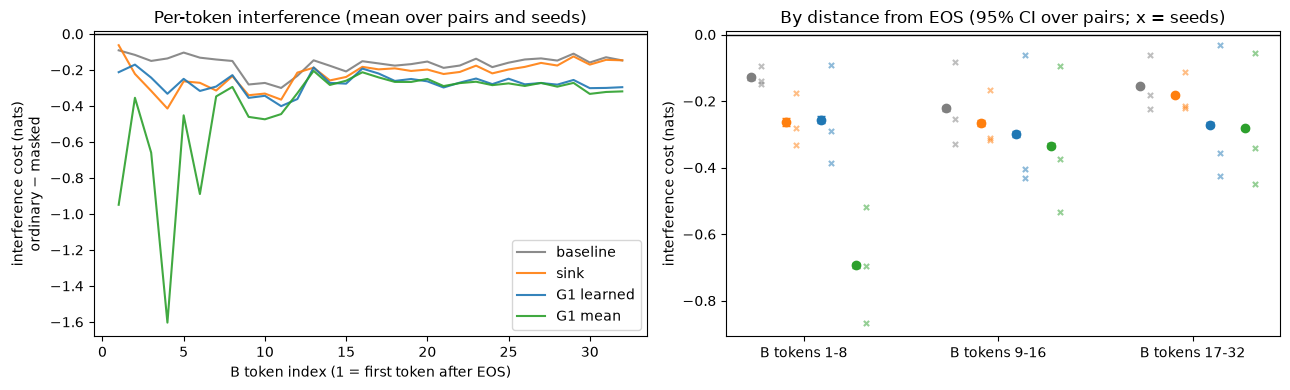

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
curve = boundary_losses.groupby(['condition', 'b_token'])[['interference']].mean().reset_index()
for name, *_ in CONDITIONS:
    c = curve[curve.condition == name]
    axes[0].plot(c.b_token, c.interference, '-', color=COLORS[name], label=name, alpha=.9)
axes[0].axhline(0, color='k', lw=1)
axes[0].set_xlabel('B token index (1 = first token after EOS)')
axes[0].set_ylabel('interference cost (nats)\nordinary − masked')
axes[0].set_title('Per-token interference (mean over pairs and seeds)')
axes[0].legend()
bins = ['1-8', '9-16', '17-32']
for i, (name, *_) in enumerate(CONDITIONS):
    d = interference_table[interference_table.condition == name]
    x = np.arange(3) + (i - 1.5) * 0.18
    axes[1].errorbar(x, d.interference, yerr=[d.interference - d.ci_low, d.ci_high - d.interference],
                     fmt='o', color=COLORS[name], capsize=3, label=name)
    for s in SEEDS:
        axes[1].scatter(x + 0.05, per_seed_interf.loc[name][s].reindex(bins).values, color=COLORS[name], marker='x', s=14, alpha=.5)
axes[1].axhline(0, color='k', lw=1)
axes[1].set_xticks(range(3), [f'B tokens {b}' for b in bins])
axes[1].set_ylabel('interference cost (nats)')
axes[1].set_title('By distance from EOS (95% CI over pairs; x = seeds)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_interference_by_distance.png', dpi=150)
plt.show()

### Does it matter whether A and B share a character name?

A descriptive split of the natural pairs (flag saved in notebook 01: some capitalized word that is not sentence-initial appears in both stories).

In [9]:
bl = boundary_losses.merge(pairs[['pair_id', 'shared_capitalized']], on='pair_id')
bl.groupby(['condition', 'shared_capitalized']).interference.agg(['mean', 'size']).unstack().round(4)

mean            size       
shared_capitalized   False   True    False  True 
condition                                        
G1 learned         -0.2712 -0.3209  181152  10848
G1 mean            -0.3964 -0.4293  181152  10848
baseline           -0.1634 -0.1911  181152  10848
sink               -0.2225 -0.2400  181152  10848

## Part B: controlled name intrusion

For each matched prompt pair (A with name₁ vs A with name₂, then the same B about a third person), at B's final position:

$$\text{margin}(A) = \log P(\text{name}_1) - \log P(\text{name}_2), \qquad \text{intrusion} = \text{margin}(A_{\text{name}_1}) - \text{margin}(A_{\text{name}_2}).$$

Positive intrusion ⇒ the previous story pulled B's prediction toward *its own* protagonist. The score is symmetric in the two names, so each unordered name pair counts once. Because several continuations of B are valid ("he", "she", B's own name, …) this is a measure of carry-over, not of an error. We also report the probability of **B's own protagonist** after each A, and with A masked out (intrusion must then be exactly 0 — a sanity check).

In [10]:
@torch.no_grad()
def last_logprobs(model, override, seqs, eos_idx, masked, batch_size=128):
    out = []
    for s in range(0, len(seqs), batch_size):
        sq = seqs[s:s + batch_size]
        x = pad_batch(sq)
        seg = torch.tensor(eos_idx[s:s + batch_size], device=device) if masked else None
        logits = model(x, segment_start=seg, gate_override=override)
        last = torch.tensor([len(q) - 1 for q in sq], device=device)
        out.append(torch.log_softmax(logits[torch.arange(len(sq)), last], -1).cpu())
    return torch.cat(out)


ids1, ids2, idsb = [torch.tensor(prompts[c].values) for c in ['id_1', 'id_2', 'id_b']]
b_alone_seqs = [list(t[e:]) for t, e in zip(prompts.tokens_1, prompts.eos_idx)]   # EOS + B at positions 0..
assert all(list(t1[e:]) == list(t2[e:]) for t1, t2, e in zip(prompts.tokens_1, prompts.tokens_2, prompts.eos_idx))
ar = torch.arange(len(prompts))
name_rows = []
for seed in SEEDS:
    for name, variant, use_mean in CONDITIONS:
        model, override = load_condition(variant, use_mean, seed)
        for masked in [False, True]:
            lp1 = last_logprobs(model, override, prompts.tokens_1.tolist(), prompts.eos_idx.tolist(), masked)
            lp2 = last_logprobs(model, override, prompts.tokens_2.tolist(), prompts.eos_idx.tolist(), masked)
            m1 = lp1[ar, ids1] - lp1[ar, ids2]
            m2 = lp2[ar, ids1] - lp2[ar, ids2]
            lpb = last_logprobs(model, override, b_alone_seqs, [0] * len(b_alone_seqs), False)
            name_rows.append(pd.DataFrame(dict(
                seed=seed, condition=name, access='masked' if masked else 'ordinary', prompt_id=prompts.prompt_id,
                template_a=prompts.template_a, template_b=prompts.template_b, name_1=prompts.name_1, name_2=prompts.name_2,
                margin_1=m1.numpy(), margin_2=m2.numpy(), intrusion=(m1 - m2).numpy(),
                p_name1_after_1=lp1[ar, ids1].exp().numpy(), p_name1_after_2=lp2[ar, ids1].exp().numpy(),
                p_nameb_after_1=lp1[ar, idsb].exp().numpy(), p_nameb_after_2=lp2[ar, idsb].exp().numpy(),
                p_nameb_b_alone=lpb[ar, idsb].exp().numpy())))
name_results = pd.concat(name_rows, ignore_index=True)
name_results.to_parquet(RESULTS_DIR / 'name_intrusion.parquet', index=False)
masked_max = name_results[name_results.access == 'masked'].intrusion.abs().max()
print(f'sanity: max |intrusion| with A masked = {masked_max:.2e}')
assert masked_max < 1e-3

sanity: max |intrusion| with A masked = 0.00e+00


In [11]:
def prompt_bootstrap(values, n_boot=2000, seed=0):
    v = np.asarray(values)
    idx = np.random.default_rng(seed).integers(0, len(v), size=(n_boot, len(v)))
    return v.mean(), np.percentile(v[idx].mean(1), 2.5), np.percentile(v[idx].mean(1), 97.5)


ordn = name_results[name_results.access == 'ordinary']
sa = ordn.groupby(['condition', 'prompt_id'])[['intrusion', 'p_nameb_after_1', 'p_nameb_after_2', 'p_name1_after_1', 'p_name1_after_2']].mean().reset_index()
msk = name_results[name_results.access == 'masked'].groupby(['condition', 'prompt_id']).p_nameb_after_1.mean()
rows = []
for name, *_ in CONDITIONS:
    d = sa[sa.condition == name]
    m, lo, hi = prompt_bootstrap(d.intrusion)
    rows.append(dict(condition=name, intrusion=m, ci_low=lo, ci_high=hi, frac_positive=(d.intrusion > 0).mean(),
                     **{f'intrusion_seed{s}': ordn[(ordn.condition == name) & (ordn.seed == s)].intrusion.mean() for s in SEEDS},
                     p_name1_when_A_is_name1=d.p_name1_after_1.mean(), p_name1_when_A_is_name2=d.p_name1_after_2.mean(),
                     p_B_protagonist=(d.p_nameb_after_1.mean() + d.p_nameb_after_2.mean()) / 2,
                     p_B_protagonist_A_masked=msk.loc[name].mean(),
                     p_B_protagonist_B_alone=ordn[ordn.condition == name].p_nameb_b_alone.mean()))
intrusion_table = pd.DataFrame(rows)
intrusion_table.to_csv(RESULTS_DIR / 'name_intrusion_table.csv', index=False)
intrusion_table.round(4)

,condition,intrusion,ci_low,ci_high,frac_positive,intrusion_seed0,intrusion_seed1,intrusion_seed2,p_name1_when_A_is_name1,p_name1_when_A_is_name2,p_B_protagonist,p_B_protagonist_A_masked,p_B_protagonist_B_alone
0,baseline,6.6138,6.4909,6.7273,1.0,7.7007,7.2968,4.8440,0.0450,0.0025,0.1151,0.1985,0.2003
1,sink,7.3456,7.2143,7.4815,1.0,7.6673,7.5063,6.8633,0.0509,0.0025,0.1251,0.2857,0.2509
2,G1 learned,6.0783,5.9442,6.2138,1.0,6.1133,5.6963,6.4253,0.0475,0.0037,0.1240,0.1708,0.1854
3,G1 mean,2.9748,2.9133,3.0335,1.0,4.0136,2.7419,2.1689,0.0176,0.0055,0.0793,0.0601,0.0465


Paired comparison with the baseline on the same prompts (positive = less intrusion than the baseline), and the breakdown by template.

In [12]:
pvn = sa.pivot(index='prompt_id', columns='condition', values='intrusion')
pd.DataFrame([dict(condition=c, **dict(zip(['baseline_minus_condition', 'ci_low', 'ci_high'],
                                            prompt_bootstrap(pvn['baseline'] - pvn[c]))))
              for c in ['sink', 'G1 learned', 'G1 mean']]).round(4)

,condition,baseline_minus_condition,ci_low,ci_high
0,sink,-0.7318,-0.7896,-0.6775
1,G1 learned,0.5355,0.4717,0.6012
2,G1 mean,3.6390,3.5649,3.7129


The same paired difference **within each training seed** (prompt-level CI per seed). If the sign changes across seeds, the difference between models is not robust to training randomness, however narrow the prompt-level interval is.

In [13]:
rows = []
for s in SEEDS:
    pv_s = ordn[ordn.seed == s].pivot(index='prompt_id', columns='condition', values='intrusion')
    for c in ['sink', 'G1 learned', 'G1 mean']:
        m, lo, hi = prompt_bootstrap(pv_s['baseline'] - pv_s[c])
        rows.append(dict(seed=s, condition=c, baseline_minus_condition=m, ci_low=lo, ci_high=hi))
intrusion_paired_by_seed = pd.DataFrame(rows)
intrusion_paired_by_seed.to_csv(RESULTS_DIR / 'name_intrusion_paired_by_seed.csv', index=False)
intrusion_paired_by_seed.pivot(index='condition', columns='seed', values='baseline_minus_condition').round(3)

seed,0,1,2
condition,,,
G1 learned,1.587,1.601,-1.581
G1 mean,3.687,4.555,2.675
sink,0.033,-0.209,-2.019


In [14]:
ordn.pivot_table(index='template_b', columns='condition', values='intrusion', aggfunc='mean')[[c[0] for c in CONDITIONS]].round(3)

condition,baseline,sink,G1 learned,G1 mean
template_b,,,,
0,7.723,8.758,7.303,3.444
1,5.263,5.604,4.288,2.119
2,6.240,6.537,5.845,3.217
3,7.229,8.483,6.877,3.119


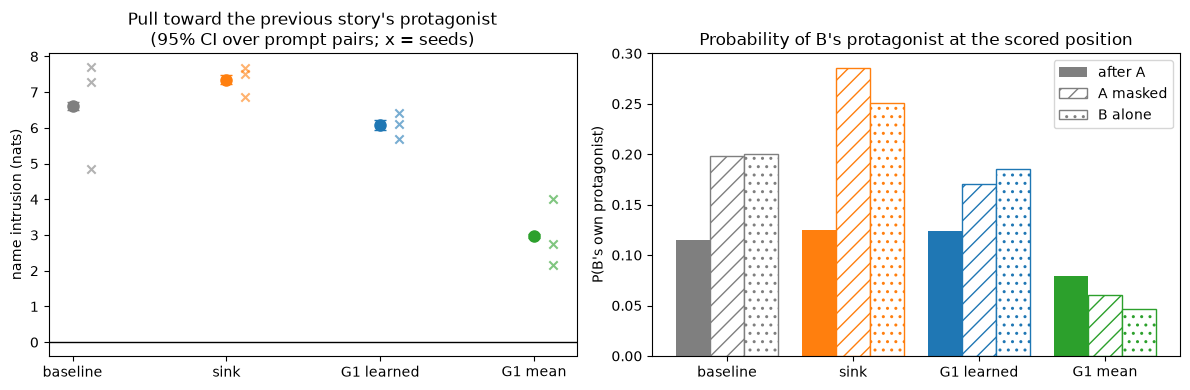

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, r in enumerate(intrusion_table.itertuples()):
    axes[0].errorbar(i, r.intrusion, yerr=[[r.intrusion - r.ci_low], [r.ci_high - r.intrusion]], fmt='o',
                     color=COLORS[r.condition], capsize=4, ms=8)
    for s in SEEDS:
        axes[0].scatter(i + 0.12, getattr(r, f'intrusion_seed{s}'), color=COLORS[r.condition], marker='x', alpha=.6)
axes[0].axhline(0, color='k', lw=1)
axes[0].set_xticks(range(len(intrusion_table)), intrusion_table.condition)
axes[0].set_ylabel('name intrusion (nats)')
axes[0].set_title('Pull toward the previous story\'s protagonist\n(95% CI over prompt pairs; x = seeds)')
x = np.arange(len(intrusion_table))
w = 0.27
axes[1].bar(x - w, intrusion_table.p_B_protagonist, w, label='after A', color=[COLORS[c] for c in intrusion_table.condition])
axes[1].bar(x, intrusion_table.p_B_protagonist_A_masked, w, label='A masked', color='white',
            edgecolor=[COLORS[c] for c in intrusion_table.condition], hatch='//')
axes[1].bar(x + w, intrusion_table.p_B_protagonist_B_alone, w, label='B alone', color='white',
            edgecolor=[COLORS[c] for c in intrusion_table.condition], hatch='..')
axes[1].set_xticks(x, intrusion_table.condition)
axes[1].set_ylabel("P(B's own protagonist)")
axes[1].set_title("Probability of B's protagonist at the scored position")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_name_intrusion.png', dpi=150)
plt.show()

## Optional: which G1 layer's gates control name intrusion?

Replace the learned gates of **one layer at a time** by their calibration means (other layers keep learned gates) and recompute intrusion. A layer whose override changes intrusion a lot is where the gate decision matters for carry-over. Only interpretable if learned-G1 intrusion is reliably non-zero.

In [16]:
rows = []
for seed in SEEDS:
    model, _ = load_condition('g1', False, seed)
    m = torch.tensor(gate_means_all[SEEDS.index(seed)], dtype=torch.float32, device=device)
    for layer in [None] + list(range(model.n_layer)):
        override = None if layer is None else {layer: m[layer]}
        lp1 = last_logprobs(model, override, prompts.tokens_1.tolist(), prompts.eos_idx.tolist(), False)
        lp2 = last_logprobs(model, override, prompts.tokens_2.tolist(), prompts.eos_idx.tolist(), False)
        intr = ((lp1[ar, ids1] - lp1[ar, ids2]) - (lp2[ar, ids1] - lp2[ar, ids2])).numpy()
        rows.append(dict(seed=seed, override='none (learned)' if layer is None else f'layer {layer} → mean',
                         intrusion=intr.mean()))
layer_override = pd.DataFrame(rows).pivot(index='override', columns='seed', values='intrusion')
layer_override['mean'] = layer_override.mean(axis=1)
layer_override.to_csv(RESULTS_DIR / 'name_intrusion_layer_override.csv')
layer_override.round(4)

seed,0,1,2,mean
override,,,,
layer 0 → mean,4.6585,4.4149,6.4191,5.1642
layer 1 → mean,6.6972,4.0214,1.4904,4.0697
layer 2 → mean,5.2924,5.4021,6.6573,5.7839
layer 3 → mean,6.1805,5.6107,4.5100,5.4337
none (learned),6.1133,5.6963,6.4253,6.0783
